In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

# Step 1: Connect Google Drive

from google.colab import drive
drive.mount('/content/drive')

# Set project directory
import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

# Check project directory
print("Project directory exists:", os.path.exists(PROJECT_PATH))
print("Project folders:", os.listdir(PROJECT_PATH))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory exists: True
Project folders: ['notebooks', 'dataset', 'results', 'models']


In [4]:

# Step 2: Load Preprocessed Data

import joblib
import os

# Define model directory
MODEL_PATH = os.path.join(PROJECT_PATH, "models")

# Load saved preprocessing data
data = joblib.load(
    os.path.join(MODEL_PATH, "processed_data.pkl")
)

# Extract ML datasets
X_train = data["X_train_ml"]
X_test = data["X_test_ml"]

# Extract target variables
y_train = data["y_train"]
y_test = data["y_test"]

# Extract class weights
class_weights = data["class_weights"]

# Display dataset information
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nClass Weights:", class_weights)


Training Features: (36168, 50)
Testing Features: (9043, 50)

Training Target: (36168,)
Testing Target: (9043,)

Class Weights: {np.int64(0): np.float64(0.5662397845758838), np.int64(1): np.float64(4.27416686362562)}


In [5]:

# Step 3: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import time

# Convert class weights into a standard dictionary
weights = {
    int(key): float(value)
    for key, value in class_weights.items()
}

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight=weights,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Random Forest Training Completed!")
print("Number of Trees:", rf_model.n_estimators)
print("Training Time:", round(training_time, 2), "seconds")


Random Forest Training Completed!
Number of Trees: 200
Training Time: 10.21 seconds


In [6]:

# Step 4: Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Predict test data
y_pred = rf_model.predict(X_test)

# Predict probabilities for ROC-AUC
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("RANDOM FOREST - MODEL EVALUATION")
print("-" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


RANDOM FOREST - MODEL EVALUATION
----------------------------------------
Accuracy  : 0.8780
Precision : 0.4782
Recall    : 0.4660
F1-Score  : 0.4720
ROC-AUC   : 0.8003

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      7985
           1       0.48      0.47      0.47      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.70      0.70      9043
weighted avg       0.88      0.88      0.88      9043


Confusion Matrix:
[[7447  538]
 [ 565  493]]


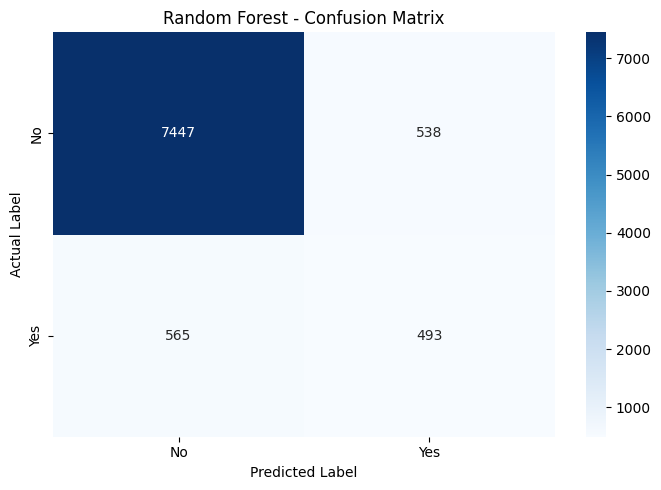

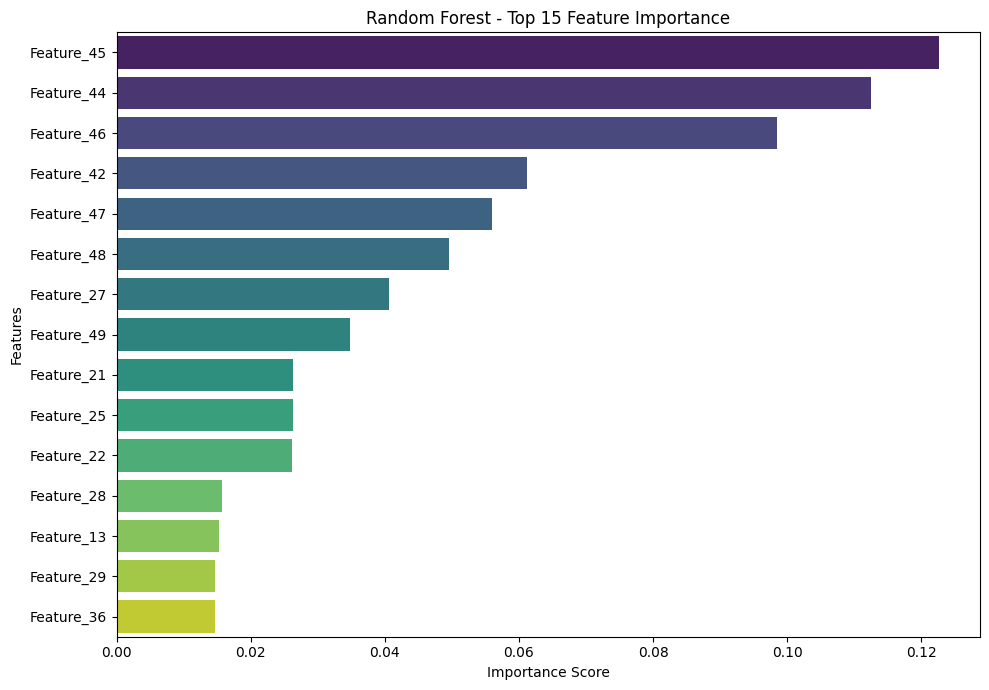

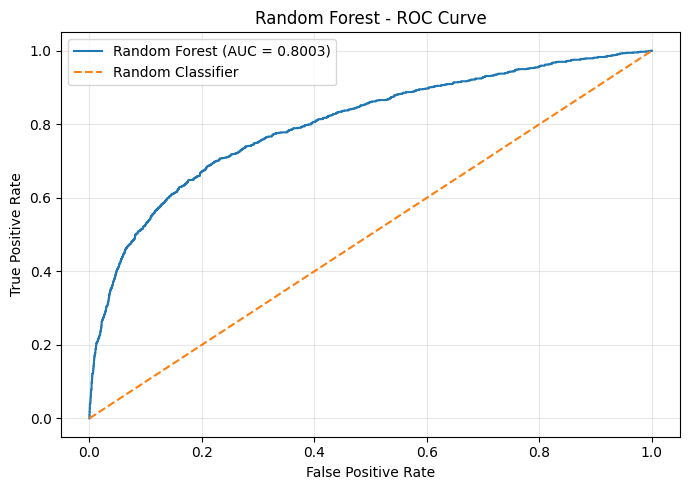

All Random Forest graphs generated and saved!

Saved files:
1. rf_confusion_matrix.png
2. rf_feature_importance.png
3. rf_roc_curve.png


In [9]:

# Step 6: Generate Random Forest Graphs

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Create graphs directory
GRAPH_PATH = os.path.join(PROJECT_PATH, "results", "graphs")
os.makedirs(GRAPH_PATH, exist_ok=True)


# 1. CONFUSION MATRIX

plt.figure(figsize=(7, 5))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "rf_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 2. FEATURE IMPORTANCE

feature_names = (
    X_train.columns.tolist()
    if hasattr(X_train, "columns")
    else [f"Feature_{i}" for i in range(X_train.shape[1])]
)

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "rf_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 3. ROC CURVE

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Random Forest - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_PATH, "rf_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("All Random Forest graphs generated and saved!")
print("\nSaved files:")

print("1. rf_confusion_matrix.png")
print("2. rf_feature_importance.png")
print("3. rf_roc_curve.png")


In [10]:

# Recover actual feature names from Day 1 preprocessing

import joblib

preprocessor = joblib.load(
    os.path.join(MODEL_PATH, "preprocessor.pkl")
)

actual_feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(actual_feature_names))
print("\nFirst 15 feature names:")

for feature in actual_feature_names[:15]:
    print(feature)


Number of features: 50

First 15 feature names:
cat__job_admin.
cat__job_blue-collar
cat__job_entrepreneur
cat__job_housemaid
cat__job_management
cat__job_retired
cat__job_self-employed
cat__job_services
cat__job_student
cat__job_technician
cat__job_unemployed
cat__job_unknown
cat__marital_divorced
cat__marital_married
cat__marital_single


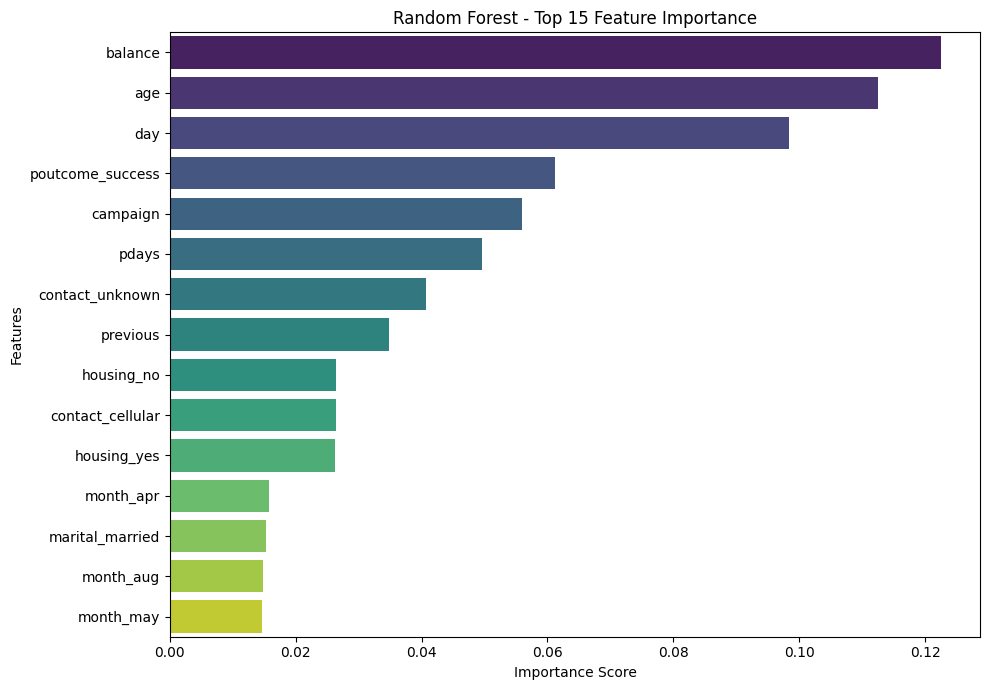

Corrected Feature Importance graph saved!

Top 15 Important Features:
         Feature  Importance
         balance    0.122602
             age    0.112476
             day    0.098407
poutcome_success    0.061192
        campaign    0.055945
           pdays    0.049535
 contact_unknown    0.040668
        previous    0.034806
      housing_no    0.026334
contact_cellular    0.026321
     housing_yes    0.026160
       month_apr    0.015782
 marital_married    0.015326
       month_aug    0.014716
       month_may    0.014691


In [11]:

# Correct Feature Importance Graph with Actual Feature Names

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": actual_feature_names,
    "Importance": rf_model.feature_importances_
})

# Remove preprocessing prefixes for cleaner labels
feature_importance["Feature"] = (
    feature_importance["Feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
)

# Select top 15 features
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Generate graph
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()

# Save corrected graph
plt.savefig(
    os.path.join(GRAPH_PATH, "rf_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Corrected Feature Importance graph saved!")
print("\nTop 15 Important Features:")
print(feature_importance.to_string(index=False))


In [12]:

# Step 7: Save Random Forest Model

import joblib
import os

# Define model save path
rf_model_path = os.path.join(
    MODEL_PATH,
    "random_forest_model.pkl"
)

# Save trained model
joblib.dump(rf_model, rf_model_path)

# Verify saved model
if os.path.exists(rf_model_path):

    print("Random Forest model saved successfully!")
    print("File path:", rf_model_path)

    # Check file size
    size = os.path.getsize(rf_model_path) / (1024 * 1024)

    print("Model file size:", round(size, 2), "MB")

else:
    print("Model saving failed!")


Random Forest model saved successfully!
File path: /content/drive/MyDrive/Marketing-Campaign-Prediction/models/random_forest_model.pkl
Model file size: 63.39 MB


In [14]:

# Step 8: Save Random Forest Evaluation Results

import json
import os
import numpy as np
from sklearn.metrics import classification_report

# Prepare evaluation results
rf_results = {
    "model_name": "Random Forest",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc),
    "training_time": float(training_time),
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(
        y_test,
        y_pred,
        output_dict=True
    ),
    "model_parameters": {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "class_weight": weights,
        "random_state": 42
    }
}

# Save results
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
os.makedirs(RESULTS_PATH, exist_ok=True)

results_file = os.path.join(
    RESULTS_PATH,
    "random_forest_results.json"
)

with open(results_file, "w") as file:
    json.dump(rf_results, file, indent=4)

print("Random Forest evaluation results saved!")
print("File path:", results_file)

print("\nSaved Metrics:")
for metric in ["accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    print(f"{metric}: {rf_results[metric]:.4f}")


Random Forest evaluation results saved!
File path: /content/drive/MyDrive/Marketing-Campaign-Prediction/results/random_forest_results.json

Saved Metrics:
accuracy: 0.8780
precision: 0.4782
recall: 0.4660
f1_score: 0.4720
roc_auc: 0.8003
